# 03 - Train and evaluate the ensemble step by step

This notebook intentionally performs the complete training workflow instead of loading the saved model. Change the hyperparameters, rerun the cells, inspect the DataFrames, and compare results.

**Important:** this notebook uses one row per track from the current `features.csv` for training. Five-second sliding-window inference is demonstrated separately in `04_sliding_window_inference.ipynb`.

## 1. Imports and paths

In [1]:
from pathlib import Path
import sys
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from xgboost import XGBClassifier

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))
FEATURES_PATH = ROOT / 'data' / 'processed' / 'features.csv'
MODEL_PATH = ROOT / 'models' / 'music_detector_pipeline.joblib'
METRICS_PATH = ROOT / 'models' / 'training_metrics.json'
RANDOM_STATE = 42
features = pd.read_csv(FEATURES_PATH)
print(f'Loaded {features.shape[0]} tracks and {features.shape[1] - 2} features.')

Loaded 440 tracks and 184 features.


## 2. Inspect the input table

The first two columns identify each track. Every remaining column is a numeric audio feature.

In [2]:
display(features.head())
display(features['label'].value_counts().rename_axis('label').to_frame('track_count'))
print('Missing values:', int(features.isna().sum().sum()))
print('Duplicate track IDs:', int(features['track_id'].duplicated().sum()))

,track_id,label,mfcc_1_mean,mfcc_1_std,mfcc_1_min,mfcc_1_max,mfcc_2_mean,mfcc_2_std,mfcc_2_min,mfcc_2_max,...,rms_1_min,rms_1_max,spectral_flatness_1_mean,spectral_flatness_1_std,spectral_flatness_1_min,spectral_flatness_1_max,tempo,duration_seconds,sample_rate,rms_energy
0,000657be-98fe-4f4c-9b00-461ea2079938,ai_generated,-284.129245,86.415079,-608.060364,-122.077232,104.899308,48.844536,-45.666626,191.560547,...,0.000724,0.150489,0.014211,0.040189,0.000010,0.308692,99.384014,30.0,22050.0,0.004470
1,0010ccca-4088-4975-9bd4-9b2985851f32,ai_generated,-213.402314,97.715446,-597.078735,-2.420801,86.410739,47.266767,-58.983459,181.761353,...,0.000016,0.172840,0.013922,0.032686,0.000006,0.472061,143.554688,30.0,22050.0,0.009201
2,0017a515-cb61-4ffc-8336-f4ef8cd6668f,ai_generated,-236.037983,86.583005,-579.426025,-44.043045,102.477890,42.297707,-29.832350,172.131577,...,0.000007,0.199950,0.018907,0.046069,0.000015,0.449174,161.499023,30.0,22050.0,0.005653
3,00206f12-4f96-45f2-bd12-45240b3789ab,ai_generated,-109.083074,70.944757,-580.971985,-12.222078,65.849952,25.781186,-47.636383,138.598877,...,0.000020,0.205560,0.030319,0.035018,0.000060,0.388791,89.102909,30.0,22050.0,0.015369
4,002fb2bd-0d98-455b-90c0-b9db06838764,ai_generated,-223.263677,79.275362,-397.679413,-22.488359,98.540387,37.070193,-1.499669,176.595306,...,0.011589,0.198099,0.018386,0.028343,0.000080,0.170580,151.999081,30.0,22050.0,0.003884


,track_count
label,
ai_generated,220
human,220


Missing values: 0
Duplicate track IDs: 0


## 3. Separate features and labels

The model receives only the 184 numeric feature columns. Labels are encoded as `0 = human` and `1 = ai_generated`.

In [3]:
feature_columns = [column for column in features.columns if column not in {'track_id', 'label'}]
X = features[feature_columns].to_numpy(dtype=np.float64)
y = (features['label'] == 'ai_generated').astype(np.int8).to_numpy()
print('X shape:', X.shape)
print('y shape:', y.shape)
print('Class values:', np.unique(y, return_counts=True))

X shape: (440, 184)
y shape: (440,)
Class values: (array([0, 1], dtype=int8), array([220, 220], dtype=int64))


## 4. Create a stratified train/test split

The test set is held out until evaluation. `stratify=y` keeps both classes balanced in both partitions. The fixed random seed makes the experiment reproducible.

In [4]:
TEST_SIZE = 0.20
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f'Train rows: {len(y_train)}')
print(f'Test rows: {len(y_test)}')
display(pd.DataFrame({'train': pd.Series(y_train).value_counts(), 'test': pd.Series(y_test).value_counts()}).fillna(0).astype(int))

Train rows: 352
Test rows: 88


,train,test
1,176,44
0,176,44


## 5. Tune the hyperparameters here

Edit these values and rerun from this cell onward. Scaling is kept inside each pipeline, so it is fitted only on training data and automatically reused for test data.

In [5]:
XGB_PARAMS = {
    'n_estimators': 200,
    'max_depth': 4,
    'learning_rate': 0.05,
    'subsample': 0.85,
    'colsample_bytree': 0.85,
}
SVM_PARAMS = {'C': 2.0, 'kernel': 'rbf', 'probability': True, 'class_weight': 'balanced'}
RF_PARAMS = {'n_estimators': 300, 'class_weight': 'balanced'}
VOTE_WEIGHTS = [2, 1, 1]
display(pd.DataFrame({'model': ['XGBoost', 'SVM', 'Random Forest'], 'parameters': [XGB_PARAMS, SVM_PARAMS, RF_PARAMS]}))

,model,parameters
0,XGBoost,"{'n_estimators': 200, 'max_depth': 4, 'learnin..."
1,SVM,"{'C': 2.0, 'kernel': 'rbf', 'probability': Tru..."
2,Random Forest,"{'n_estimators': 300, 'class_weight': 'balanced'}"


## 6. Build the three model pipelines

The ensemble uses soft voting: each model contributes a probability, and the weighted average becomes the final AI-generated probability.

In [6]:
xgb_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', XGBClassifier(**XGB_PARAMS, objective='binary:logistic', eval_metric='logloss', random_state=RANDOM_STATE, n_jobs=-1)),
])
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC(**SVM_PARAMS, random_state=RANDOM_STATE)),
])
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(**RF_PARAMS, random_state=RANDOM_STATE, n_jobs=-1)),
])
ensemble = VotingClassifier(
    estimators=[('xgboost', xgb_pipeline), ('svm', svm_pipeline), ('random_forest', rf_pipeline)],
    voting='soft', weights=VOTE_WEIGHTS, n_jobs=-1
)
display(ensemble)

VotingClassifier(estimators=[('xgboost',
                              Pipeline(steps=[('scaler', StandardScaler()),
                                              ('classifier',
                                               XGBClassifier(base_score=None,
                                                             booster=None,
                                                             callbacks=None,
                                                             colsample_bylevel=None,
                                                             colsample_bynode=None,
                                                             colsample_bytree=0.85,
                                                             device=None,
                                                             early_stopping_rounds=None,
                                                             enable_categorical=False,
                                                             eval_metric='logloss',
                                                             feature_types=None,
                                                             gamma=None,
                                                             grow_policy...
                                                             random_state=42, ...))])),
                             ('svm',
                              Pipeline(steps=[('scaler', StandardScaler()),
                                              ('classifier',
                                               SVC(C=2.0,
                                                   class_weight='balanced',
                                                   probability=True,
                                                   random_state=42))])),
                             ('random_forest',
                              Pipeline(steps=[('scaler', StandardScaler()),
                                              ('classifier',
                                               RandomForestClassifier(class_weight='balanced',
                                                                      n_estimators=300,
                                                                      n_jobs=-1,
                                                                      random_state=42))]))],
                 n_jobs=-1, voting='soft', weights=[2, 1, 1])

## 7. Train each model separately for comparison

In [7]:
individual_models = {'XGBoost': xgb_pipeline, 'SVM': svm_pipeline, 'Random Forest': rf_pipeline}
individual_results = []
for name, model in individual_models.items():
    model.fit(X_train, y_train)
    probabilities = model.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(np.int8)
    individual_results.append({'model': name, 'accuracy': accuracy_score(y_test, predictions), 'roc_auc': roc_auc_score(y_test, probabilities)})
display(pd.DataFrame(individual_results).sort_values('roc_auc', ascending=False))

,model,accuracy,roc_auc
1,SVM,0.931818,0.987087
2,Random Forest,0.943182,0.978048
0,XGBoost,0.920455,0.976756


## 8. Train the soft-voting ensemble

In [8]:
ensemble.fit(X_train, y_train)
test_probabilities = ensemble.predict_proba(X_test)[:, 1]
test_predictions = (test_probabilities >= 0.5).astype(np.int8)
metrics = {
    'test_accuracy': accuracy_score(y_test, test_predictions),
    'test_roc_auc': roc_auc_score(y_test, test_probabilities),
}
display(pd.DataFrame([metrics]))
print(classification_report(y_test, test_predictions, target_names=['human', 'ai_generated']))

,test_accuracy,test_roc_auc
0,0.931818,0.982438


              precision    recall  f1-score   support

       human       0.93      0.93      0.93        44
ai_generated       0.93      0.93      0.93        44

    accuracy                           0.93        88
   macro avg       0.93      0.93      0.93        88
weighted avg       0.93      0.93      0.93        88



## 9. Inspect errors and confidence

In [9]:
results = pd.DataFrame({'actual': y_test, 'ai_probability': test_probabilities, 'prediction': test_predictions})
results['actual_label'] = results['actual'].map({0: 'human', 1: 'ai_generated'})
results['predicted_label'] = results['prediction'].map({0: 'human', 1: 'ai_generated'})
results['correct'] = results['actual'] == results['prediction']
display(results.sort_values('ai_probability', ascending=False).head(20))
display(results[~results['correct']])

,actual,ai_probability,prediction,actual_label,predicted_label,correct
49,1,0.992538,1,ai_generated,ai_generated,True
51,1,0.987798,1,ai_generated,ai_generated,True
17,1,0.985504,1,ai_generated,ai_generated,True
10,1,0.983302,1,ai_generated,ai_generated,True
46,1,0.981350,1,ai_generated,ai_generated,True
77,1,0.979056,1,ai_generated,ai_generated,True
47,1,0.977014,1,ai_generated,ai_generated,True
62,1,0.976257,1,ai_generated,ai_generated,True
38,1,0.973663,1,ai_generated,ai_generated,True
74,1,0.969730,1,ai_generated,ai_generated,True


,actual,ai_probability,prediction,actual_label,predicted_label,correct
3,1,0.339302,0,ai_generated,human,False
32,0,0.587681,1,human,ai_generated,False
42,0,0.939035,1,human,ai_generated,False
43,1,0.352284,0,ai_generated,human,False
63,0,0.536833,1,human,ai_generated,False
84,1,0.346597,0,ai_generated,human,False


## 10. Plot evaluation results

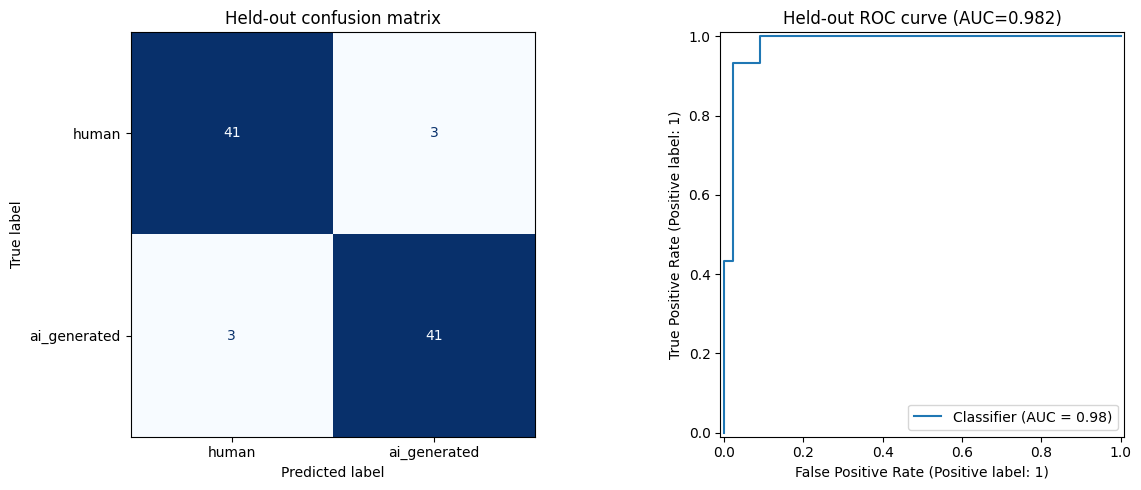

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, test_predictions), display_labels=['human', 'ai_generated']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title('Held-out confusion matrix')
RocCurveDisplay.from_predictions(y_test, test_probabilities, ax=axes[1])
axes[1].set_title(f"Held-out ROC curve (AUC={metrics['test_roc_auc']:.3f})")
plt.tight_layout()
plt.show()

## 11. Inspect XGBoost feature importance

This is one model's importance view, not a causal explanation. It is useful for experimentation and for deciding which feature groups to investigate.

,feature,importance
6,mfcc_2_min,0.041847
78,mfcc_20_min,0.036079
86,chroma_2_min,0.031802
82,chroma_1_min,0.024547
90,chroma_3_min,0.023322
175,rms_1_max,0.020349
3,mfcc_1_max,0.020306
75,mfcc_19_max,0.017585
176,spectral_flatness_1_mean,0.017168
168,zero_crossing_rate_1_mean,0.016808


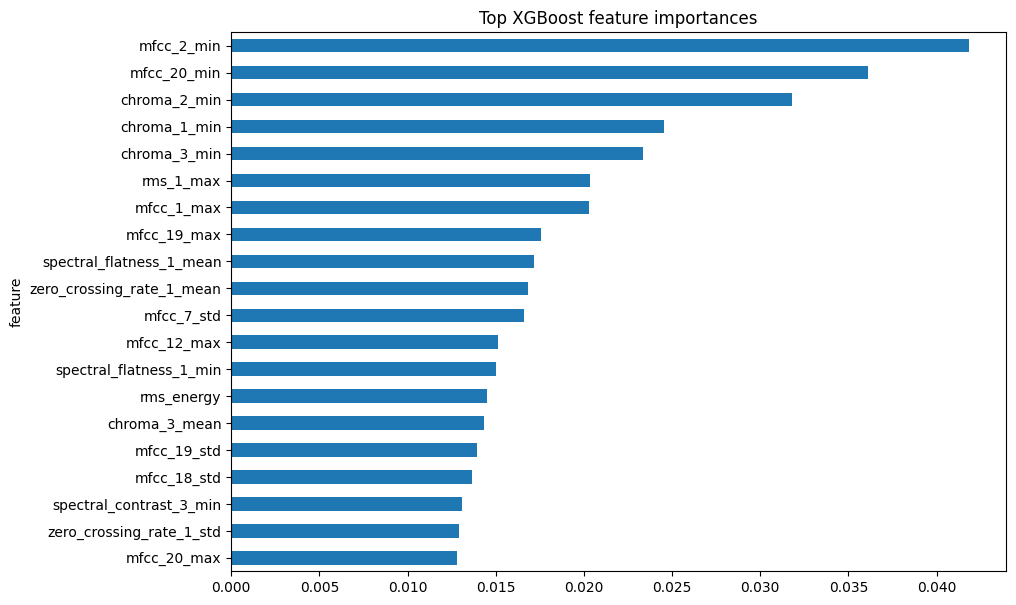

In [11]:
xgb_classifier = ensemble.named_estimators_['xgboost'].named_steps['classifier']
importance = pd.DataFrame({'feature': feature_columns, 'importance': xgb_classifier.feature_importances_}).sort_values('importance', ascending=False)
display(importance.head(25))
importance.head(20).sort_values('importance').plot.barh(x='feature', y='importance', figsize=(10, 7), legend=False)
plt.title('Top XGBoost feature importances')
plt.show()

## 12. Save the notebook-trained model (optional)

This saves the same artifact shape used by the command-line pipeline. Run this only after you are satisfied with the experiment.

In [12]:
save_artifact = True
if save_artifact:
    MODEL_PATH.parent.mkdir(parents=True, exist_ok=True)
    joblib.dump({'model': ensemble, 'feature_columns': feature_columns, 'label_mapping': {'human': 0, 'ai_generated': 1}}, MODEL_PATH)
    METRICS_PATH.write_text(json.dumps({**metrics, 'feature_count': len(feature_columns), 'random_state': RANDOM_STATE}, indent=2), encoding='utf-8')
    print(f'Saved model to {MODEL_PATH}')
    print(f'Saved metrics to {METRICS_PATH}')

Saved model to e:\ai-music-detector\models\music_detector_pipeline.joblib
Saved metrics to e:\ai-music-detector\models\training_metrics.json
